# Task 1 (Level 1) : Task: Data Exploration and Preprocessing

-           Explore the dataset and identify the number of rows and columns.


We check the number of rows and columns to understand the dataset size.
Displaying the first few records helps verify that the data is imported correctly and shows the general structure of the dataset.

In [3]:
import pandas as pd
pd.options.display.max_columns = 50
df = pd.read_csv("Dataset .csv")  
print("Shape (rows, columns):", df.shape)
df.head(6)

Shape (rows, columns): (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
5,18189371,Din Tai Fung,162,Mandaluyong City,"Ground Floor, Mega Fashion Hall, SM Megamall, ...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056314,14.583764,Chinese,1000,Botswana Pula(P),No,No,No,No,3,4.4,Green,Very Good,336


-           Column types and summary

This step identifies which columns are numerical and which are categorical.

Numerical columns will be used for statistical analysis and modeling

Categorical columns help in grouping, filtering, and visualization describe() helps us understand key statistics like mean, median, min, max, standard deviation, etc.

In [4]:
print("\n--- Column data types ---")
print(df.dtypes)
print("\n--- Numeric summary (describe) ---")
display(df.describe(include='number').transpose())
print("\n--- Non-numeric summary (top values) ---")
display(df.describe(include='object').transpose())



--- Column data types ---
Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             object
Rating text              object
Votes                     int64
dtype: object

--- Numeric summary (describe) ---


,count,mean,std,min,25%,50%,75%,max
Restaurant ID,9551.0,9.051128e+06,8.791521e+06,53.000000,301962.500000,6.004089e+06,1.835229e+07,1.850065e+07
Country Code,9551.0,1.836562e+01,5.675055e+01,1.000000,1.000000,1.000000e+00,1.000000e+00,2.160000e+02
Longitude,9551.0,6.412657e+01,4.146706e+01,-157.948486,77.081343,7.719196e+01,7.728201e+01,1.748321e+02
Latitude,9551.0,2.585438e+01,1.100794e+01,-41.330428,28.478713,2.857047e+01,2.864276e+01,5.597698e+01
Average Cost for two,9551.0,1.199211e+03,1.612118e+04,0.000000,250.000000,4.000000e+02,7.000000e+02,8.000000e+05
Price range,9551.0,1.804837e+00,9.056088e-01,1.000000,1.000000,2.000000e+00,2.000000e+00,4.000000e+00
Aggregate rating,9551.0,2.666370e+00,1.516378e+00,0.000000,2.500000,3.200000e+00,3.700000e+00,4.900000e+00
Votes,9551.0,1.569097e+02,4.301691e+02,0.000000,5.000000,3.100000e+01,1.310000e+02,1.093400e+04



--- Non-numeric summary (top values) ---


,count,unique,top,freq
Restaurant Name,9551,7446,Cafe Coffee Day,83
City,9551,141,New Delhi,5473
Address,9551,8918,"Sector 41, Noida",11
Locality,9551,1208,Connaught Place,122
Locality Verbose,9551,1265,"Connaught Place, New Delhi",122
Cuisines,9542,1825,North Indian,936
Currency,9551,12,Indian Rupees(Rs.),8652
Has Table booking,9551,2,No,8393
Has Online delivery,9551,2,No,7100
Is delivering now,9551,2,No,9517


-           Missing values — counts and percent

Missing data affects analysis accuracy

We must decide whether to drop or fill missing values

Columns with high missing percentages need special handling

In [5]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(3)
missing = pd.DataFrame({"missing_count": missing_count, "missing_percent": missing_percent}).sort_values("missing_percent", ascending=False)
missing.head(40)   # show top columns with missing values


,missing_count,missing_percent
Cuisines,9,0.094
Restaurant Name,0,0.000
Country Code,0,0.000
City,0,0.000
Restaurant ID,0,0.000
Address,0,0.000
Locality,0,0.000
Longitude,0,0.000
Locality Verbose,0,0.000
Latitude,0,0.000


-           Sample rows that have any missing value

We inspect some rows that contain missing values.

In [6]:
rows_with_missing = df[df.isnull().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
rows_with_missing.head(8)


Rows containing at least one missing value: 9


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
84,17284105,Cookie Shoppe,216,Albany,"115 N Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.154000,31.577200,NaN,0,Dollar($),No,No,No,No,1,3.4,Orange,Average,34
87,17284211,Pearly's Famous Country Cookng,216,Albany,"814 N Slappey Blvd, Albany, GA 31701",Albany,"Albany, Albany",-84.175900,31.588200,NaN,0,Dollar($),No,No,No,No,1,3.4,Orange,Average,36
94,17284158,Jimmie's Hot Dogs,216,Albany,"204 S Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.153400,31.575100,NaN,10,Dollar($),No,No,No,No,1,3.9,Yellow,Good,160
297,17374552,Corkscrew Cafe,216,Gainesville,"51 W Main St, Dahlonega, GA 30533",Dahlonega,"Dahlonega, Gainesville",-83.985800,34.531800,NaN,40,Dollar($),No,No,No,No,3,3.9,Yellow,Good,209
328,17501439,Dovetail,216,Macon,"543 Cherry St, Macon, GA 31201",Macon,"Macon, Macon",-83.627979,32.836410,NaN,40,Dollar($),No,No,No,No,3,3.8,Yellow,Good,102
346,17606621,HI Lite Bar & Lounge,216,Miller,"109 N Broadway Ave, Miller, SD 57362",Miller,"Miller, Miller",-98.989100,44.515800,NaN,0,Dollar($),No,No,No,No,1,3.4,Orange,Average,11
368,17059060,Hillstone,216,Orlando,"215 South Orlando Avenue, Winter Park, FL 32789",Winter Park,"Winter Park, Orlando",-81.365260,28.596682,NaN,40,Dollar($),No,No,No,No,3,4.4,Green,Very Good,1158
418,17142698,Leonard's Bakery,216,Rest of Hawaii,"933 Kapahulu Ave, Honolulu, HI 96816",Kaimuki,"Kaimuki, Rest of Hawaii",-157.813432,21.284586,NaN,10,Dollar($),No,No,No,No,1,4.7,Dark Green,Excellent,707


-           Aggregate rating

Aggregate rating is the target variable for modeling tasks.

Count (non-null): 9551
Total rows: 9551
Missing in Aggregate rating: 0 (0.000%)

Aggregate rating summary statistics:
count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64

Aggregate rating value counts (including NaN):
Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64


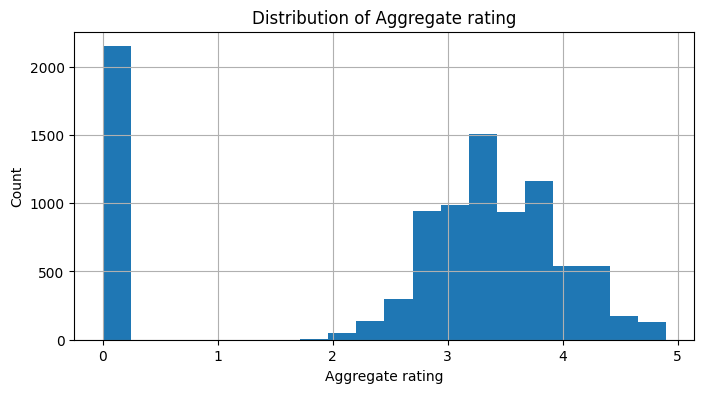

In [7]:
agg = df["Aggregate rating"]
print("Count (non-null):", agg.count())
print("Total rows:", len(df))
print("Missing in Aggregate rating:", agg.isnull().sum(), "({:.3f}%)".format(agg.isnull().sum()/len(df)*100))
print("\nAggregate rating summary statistics:")
print(agg.describe())

# value counts (sorted)
vc = agg.value_counts(dropna=False).sort_index()
print("\nAggregate rating value counts (including NaN):")
print(vc)

# histogram
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(agg.dropna(), bins=20)
plt.title("Distribution of Aggregate rating")
plt.xlabel("Aggregate rating")
plt.ylabel("Count")
plt.grid(True)
plt.show()


-           Quick bucket analysis

Helps understand the distribution in different quality levels and identify class imbalance, which is useful for later modeling and analysis.

Rating bucket counts:
Aggregate rating
Poor (0-2)           2158
Average (2-3.5)      4393
Good (3.5-4.5)       2794
Excellent (4.5-5)     206
Name: count, dtype: int64


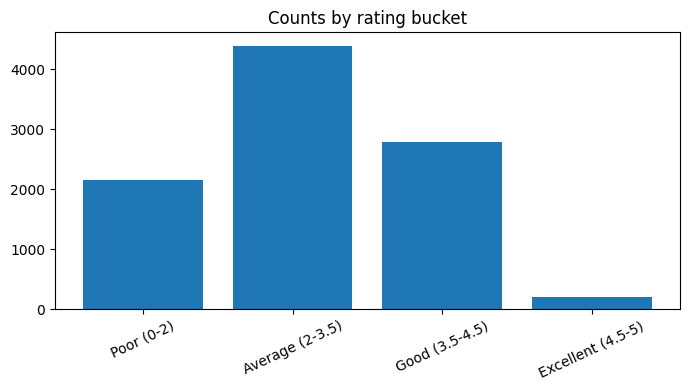

In [8]:
bins = [0, 2, 3.5, 4.5, 5.0]
labels = ['Poor (0-2)', 'Average (2-3.5)', 'Good (3.5-4.5)', 'Excellent (4.5-5)']
bucket = pd.cut(df['Aggregate rating'].dropna(), bins=bins, labels=labels, include_lowest=True)
bucket_counts = bucket.value_counts().reindex(labels, fill_value=0)
print("Rating bucket counts:")
print(bucket_counts)

plt.figure(figsize=(7,4))
plt.bar(bucket_counts.index.astype(str), bucket_counts.values)
plt.title("Counts by rating bucket")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


-           Actions for missing data

In [ ]:
clean_df = df.copy()

print("Aggregate missing percent:", df['Aggregate rating'].isnull().sum() / len(df) * 100)
clean_df = clean_df.dropna(subset=['Aggregate rating'])

for col in ['Cuisines', 'Locality', 'Locality Verbose', 'Address']:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].fillna('Unknown')

print("Lat/Long missing counts:", clean_df['Latitude'].isnull().sum(), clean_df['Longitude'].isnull().sum())

if 'Average Cost for two' in clean_df.columns:
    clean_df['Average Cost for two'] = clean_df['Average Cost for two'].fillna(clean_df['Average Cost for two'].median())

clean_df.to_csv("dataset_level1_cleaned.csv", index=False)
print("Cleaned dataset saved as dataset_level1_cleaned.csv")


Aggregate missing percent: 0.0
Lat/Long missing counts: 0 0
Cleaned dataset saved as dataset_level1_cleaned.csv


-           Quick sanity checks after cleaning

Make the dataset clean, consistent, and ready for further analysis in Level 2 and Level 3.

In [10]:
clean = pd.read_csv("dataset_level1_cleaned.csv")
print("After-clean shape:", clean.shape)
print("Missing summary (after):")
print(clean.isnull().sum().sort_values(ascending=False).head(20))


After-clean shape: (9551, 21)
Missing summary (after):
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
dtype: int64
